# 07 — Q10: atividades mais usadas × desempenho

**CRISP-DM, fases 4 e 5** · corresponde à seção **§7.4** de `docs/DOCUMENTACAO.md` e ao problema 3 da §13

> **Q10 — Quais tipos de atividades apresentam maior frequência de utilização e maior relação com o desempenho dos estudantes?**

A pergunta tem duas partes:
- **frequência de utilização:** quanto cada atividade é usada, medida em eventos e em estudantes que a usam;
- **relação com o desempenho:** se quem usa mais a atividade tem desempenho melhor, descontando o nível inicial e o volume total de uso.

Neste notebook:
1. Denominadores: **eventos × estudantes usuários × acessos**
2. ARES: uso, correlação parcial, controle de volume e correção de Holm
3. EdNet: origens (partição) × acessos (sobreposição), % sobre todos × % sobre ativos
4. Conclusão e conferência com os resultados oficiais

In [1]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
from scipy import stats
from utils import partial_spearman, ajuste_multiplo

Projeto: C:\Users\braia\OneDrive\Documentos\GitHub\Datasets-Beready


## 1. ARES

### 1.1 Frequência de utilização: os denominadores

- **% dos eventos:** eventos da atividade ÷ **todos os eventos de aprendizagem** dos 192 alunos (sem os alertas do sistema).
- **% de alunos que usam:** alunos com ≥ 1 evento da atividade ÷ **192** alunos com log.
- **Correlações:** só os **141** alunos com pré, pós e log.

In [2]:
a = pd.read_csv(C.PROCESSED / "ares_alunos.csv")
log = a[a["n_interacoes"] > 0]
perf = log.dropna(subset=["nota_pre", "nota_pos"])
ATIV = [c for c in a.columns if c.startswith("ativ::") and "Alertas" not in c]
total_eventos = log[ATIV].sum().sum()
print(f"Eventos de aprendizagem (denominador): {total_eventos:,}".replace(",", "."))
uso = pd.DataFrame({
    "eventos": log[ATIV].sum(),
    "% dos eventos": log[ATIV].sum() / total_eventos * 100,
    "% dos 192 alunos que usam": (log[ATIV] > 0).mean() * 100,
    "% dos 141 alunos que usam": (perf[ATIV] > 0).mean() * 100,
    "média por aluno": log[ATIV].mean(),
})
uso.index = [c[6:] for c in uso.index]
uso.sort_values("eventos", ascending=False).round(1)

Eventos de aprendizagem (denominador): 87.391


,eventos,% dos eventos,% dos 192 alunos que usam,% dos 141 alunos que usam,média por aluno
Responder questões/tarefas,41803,47.8,100.0,100.0,217.7
Navegação entre páginas,12395,14.2,100.0,100.0,64.6
Vocabulário (palavras e traduções),10317,11.8,96.9,97.2,53.7
Leitura de textos,9476,10.8,100.0,100.0,49.4
Avaliação do texto (estrelas),6202,7.1,100.0,100.0,32.3
Acesso (login),2293,2.6,100.0,100.0,11.9
Outros (diálogos/botões),1842,2.1,96.9,98.6,9.6
Turmas (entrar/sair),1802,2.1,100.0,100.0,9.4
Tutorial,779,0.9,100.0,100.0,4.1
Visualização de feedback/nota,482,0.6,22.4,26.2,2.5


### 1.2 Relação com o desempenho

Duas versões de correlação parcial com a nota no pós-teste:
- **controlando o pré-teste:** entre alunos de mesmo nível inicial, quem usa mais a atividade tira nota maior?
- **controlando o pré-teste e o volume total:** a atividade tem relação *própria*, além de “usar mais a plataforma”?

Como são **10 atividades**, os p-valores são corrigidos por **Holm**.

In [3]:
vol = pd.DataFrame({"pre": perf["nota_pre"], "log_volume": np.log(perf["n_interacoes"])})
linhas = []
for c in ATIV:
    p1 = partial_spearman(perf[c], perf["nota_pos"], perf["nota_pre"])
    p2 = partial_spearman(perf[c], perf["nota_pos"], vol)
    linhas.append({"atividade": c[6:], "ρ parcial (pré)": p1["rho_parcial"], "p": p1["p"],
                   "ρ parcial (pré + volume)": p2["rho_parcial"], "p (pré + volume)": p2["p"]})
t_ares = pd.DataFrame(linhas)
t_ares["p Holm"] = ajuste_multiplo(t_ares["p"])[0]
t_ares["p Holm (pré + volume)"] = ajuste_multiplo(t_ares["p (pré + volume)"])[0]
t_ares["significativo após Holm?"] = np.where(t_ares["p Holm"] < 0.05, "sim", "não")
t_ares.sort_values("p").round(3)

,atividade,ρ parcial (pré),p,ρ parcial (pré + volume),p (pré + volume),p Holm,p Holm (pré + volume),significativo após Holm?
7,Tutorial,-0.234,0.005,-0.239,0.005,0.054,0.047,não
9,Vocabulário (palavras e traduções),0.172,0.043,0.164,0.054,0.383,0.486,não
1,Avaliação do texto (estrelas),-0.056,0.508,-0.083,0.332,1.000,1.000,não
8,Visualização de feedback/nota,-0.043,0.616,-0.056,0.516,1.000,1.000,não
4,Outros (diálogos/botões),0.040,0.635,0.018,0.838,1.000,1.000,não
5,Responder questões/tarefas,0.039,0.647,-0.015,0.862,1.000,1.000,não
3,Navegação entre páginas,-0.038,0.652,-0.109,0.203,1.000,1.000,não
2,Leitura de textos,-0.031,0.720,-0.104,0.221,1.000,1.000,não
6,Turmas (entrar/sair),-0.022,0.796,-0.031,0.720,1.000,1.000,não
0,Acesso (login),-0.004,0.964,-0.035,0.682,1.000,1.000,não


**Leitura:**
- Sem correção, **vocabulário** (p = 0,042) e **tutorial** (p = 0,005) pareceriam significativos.
- **Com Holm**, vocabulário vai a 0,38 e o tutorial fica **no limite** (0,054; 0,047 controlando também o volume).
- ➡️ Nenhuma atividade tem relação firme com a nota. O tutorial é, no máximo, uma hipótese para investigar.

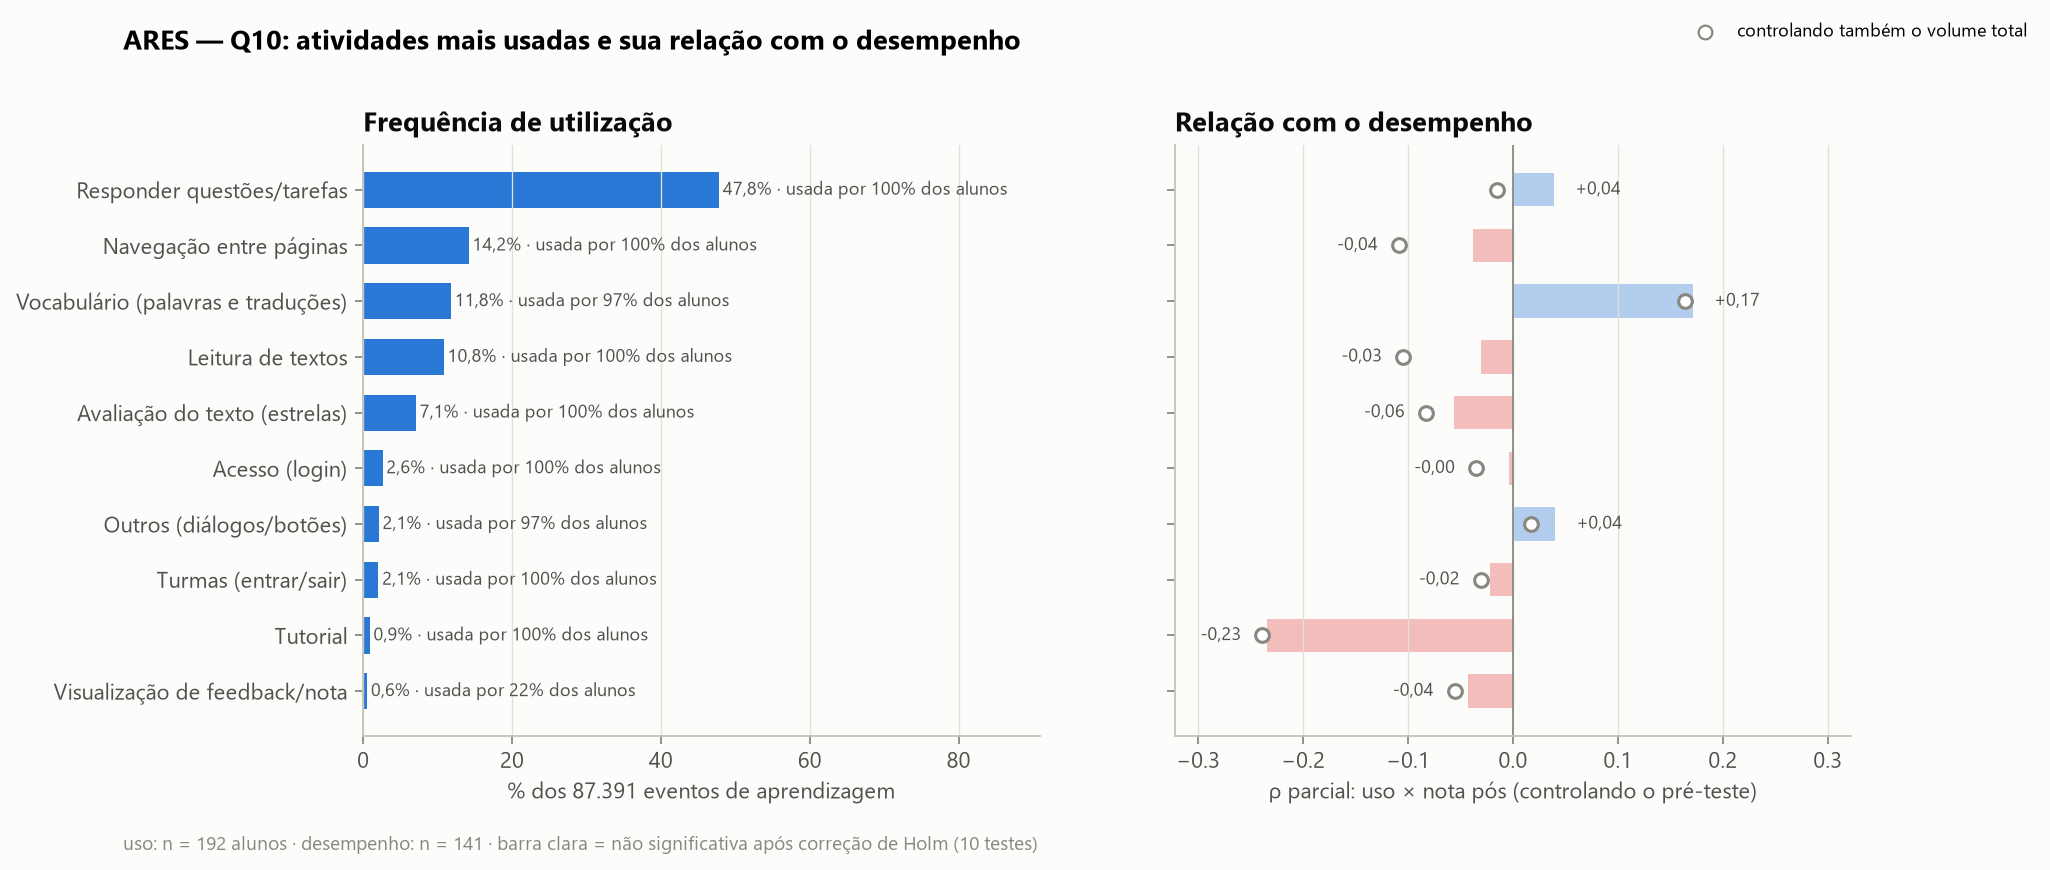

In [4]:
Image(filename=str(C.FIG / "ares" / "Q10_atividades_desempenho.png"))

## 2. EdNet

### 2.1 Origens × acessos: o que pode e o que não pode ser somado

- As **8 origens** (`source`: sprint, diagnosis…) formam uma **partição**: cada evento tem exatamente uma origem, e a soma delas é o total de eventos.
- **Explicações e aulas** são **acessos** (eventos `enter` em itens `e…` e `l…`). Cada acesso **já está contado** dentro de alguma origem. Por isso não têm “% dos eventos” e não podem ser somados às origens.

In [5]:
u = pd.read_csv(C.PROCESSED / "ednet_users.csv.gz")
SRC = {"src_sprint": "Prática por parte (sprint)", "src_diagnosis": "Diagnóstico inicial", "src_adaptive_offer": "Recomendação adaptativa",
       "src_review_quiz": "Quiz de revisão", "src_my_note": "Caderno de erros/anotações", "src_archive": "Questões salvas (arquivo)",
       "src_tutor": "Tutor", "src_review": "Revisão"}
ACESSOS = {"acessos_explicacao": "Leitura de explicações (feedback)", "acessos_aula": "Aulas (vídeo/texto)"}
print("As 8 origens somam exatamente o total de eventos de cada estudante:", bool((u[list(SRC)].sum(axis=1) == u["n_eventos"]).all()))

import ednet_01_extract as X
if C.EDNET_BRUTO_DISPONIVEL:
    d = X.ler_estudante("u10276")
    exp = d[(d["action_type"] == "enter") & d["item_id"].str.startswith("e")]
    print("Exemplo (u10276): os acessos a explicações já têm uma origem →", exp["source"].value_counts().to_dict())

As 8 origens somam exatamente o total de eventos de cada estudante: True


Exemplo (u10276): os acessos a explicações já têm uma origem → {'sprint': 63, 'review': 4, 'adaptive_offer': 4}


### 2.2 Frequência de utilização: % sobre todos × % sobre ativos

62,5% dos estudantes só fizeram o diagnóstico. Calcular “% que usa” sobre **todos** faz qualquer atividade parecer pouco usada. Por isso também é mostrado o percentual sobre os **ativos** (que foram além do diagnóstico):

In [6]:
ativos = u[u["n_eventos"] > u["src_diagnosis"]]
f = lambda v: f"{v:,}".replace(",", ".")
print(f"Todos: {f(len(u))} | ativos: {f(len(ativos))}")
linhas = []
for c, nome in (SRC | ACESSOS).items():
    origem = c.startswith("src_")
    s = c[4:] if origem else None
    linhas.append({"atividade": nome, "tipo": "origem" if origem else "acessos (sobrepõe)",
                   "eventos/acessos": int(u[c].sum()),
                   "% dos eventos": round(u[c].sum() / u["n_eventos"].sum() * 100, 2) if origem else None,
                   "% de TODOS que usam": round((u[c] > 0).mean() * 100, 1),
                   "% dos ATIVOS que usam": round((ativos[c] > 0).mean() * 100, 1),
                   "acurácia dentro da atividade": round(u[f"acerto_{s}"].sum() / u[f"resp_{s}"].sum(), 3)
                   if origem and f"resp_{s}" in u and u[f"resp_{s}"].sum() else None})
uso_e = pd.DataFrame(linhas).sort_values("eventos/acessos", ascending=False)
uso_e

Todos: 297.915 | ativos: 111.748


,atividade,tipo,eventos/acessos,% dos eventos,% de TODOS que usam,% dos ATIVOS que usam,acurácia dentro da atividade
0,Prática por parte (sprint),origem,64616840,72.44,33.3,88.9,0.664
8,Leitura de explicações (feedback),acessos (sobrepõe),15853221,NaN,36.3,96.7,NaN
4,Caderno de erros/anotações,origem,7033452,7.89,13.5,36.1,0.631
1,Diagnóstico inicial,origem,6621642,7.42,96.1,89.7,0.474
2,Recomendação adaptativa,origem,5122323,5.74,15.0,39.9,0.781
3,Quiz de revisão,origem,3620216,4.06,6.2,16.5,0.737
7,Revisão,origem,803141,0.90,4.4,11.9,0.779
6,Tutor,origem,722038,0.81,3.7,9.8,0.634
5,Questões salvas (arquivo),origem,655224,0.73,7.9,21.0,NaN
9,Aulas (vídeo/texto),acessos (sobrepõe),601805,NaN,14.4,38.3,NaN


➡️ A prática por parte tem **72% dos eventos**. Sobre todos os estudantes, ela parece usada por só 33%; entre os ativos, **89%** a usam. A recomendação adaptativa tem a **maior acurácia interna** (78%) porque oferece questões calibradas para o aluno, o que não significa que ela melhore o desempenho.

### 2.3 Relação com o desempenho

Desempenho = acurácia fora do diagnóstico. Controle = acurácia no diagnóstico (o “pré-teste”). Base: 66.062 estudantes com diagnóstico ≥ 5 e ≥ 10 questões depois.

In [7]:
nd = u["n_respondidas"] - u["resp_diagnosis"]
u["acc_pos"] = np.where(nd >= C.EDNET_MIN_ANSWERS, (u["n_acertos"] - u["acerto_diagnosis"]) / nd.clip(lower=1), np.nan)
u["acc_diag"] = np.where(u["resp_diagnosis"] >= 5, u["acerto_diagnosis"] / u["resp_diagnosis"].clip(lower=1), np.nan)
ctrl = u.dropna(subset=["acc_pos", "acc_diag"])
vol = pd.DataFrame({"diag": ctrl["acc_diag"], "log_volume": np.log(ctrl["n_eventos"])})
print("Estudantes:", f(len(ctrl)))
linhas = []
for c, nome in (SRC | ACESSOS).items():
    linhas.append({"atividade": nome,
                   "ρ parcial (diagnóstico)": partial_spearman(ctrl[c], ctrl["acc_pos"], ctrl["acc_diag"])["rho_parcial"],
                   "ρ parcial (diagnóstico + volume)": partial_spearman(ctrl[c], ctrl["acc_pos"], vol)["rho_parcial"]})
t_ed = pd.DataFrame(linhas).sort_values("ρ parcial (diagnóstico)", ascending=False)
t_ed

Estudantes: 66.062


,atividade,ρ parcial (diagnóstico),ρ parcial (diagnóstico + volume)
0,Prática por parte (sprint),0.1632,0.0999
8,Leitura de explicações (feedback),0.1422,0.0184
5,Questões salvas (arquivo),0.0804,0.0119
3,Quiz de revisão,0.0787,0.0114
7,Revisão,0.0419,0.0064
4,Caderno de erros/anotações,0.0395,-0.0463
9,Aulas (vídeo/texto),0.0356,-0.0953
6,Tutor,0.0293,-0.0072
2,Recomendação adaptativa,0.0093,-0.1612
1,Diagnóstico inicial,-0.0456,-0.0525


**Leitura:** com 66 mil estudantes, até ρ de ±0,01 pode ser “significativo”, então a leitura é pela **magnitude**.
- A **prática** tem a maior relação (+0,16, **fraca**) e mantém parte dela controlando o volume (+0,10).
- A **leitura de explicações** (+0,14) **some** com o controle de volume (+0,02): ela acompanha a quantidade de prática, mas não tem relação própria.
- O resto é desprezível.

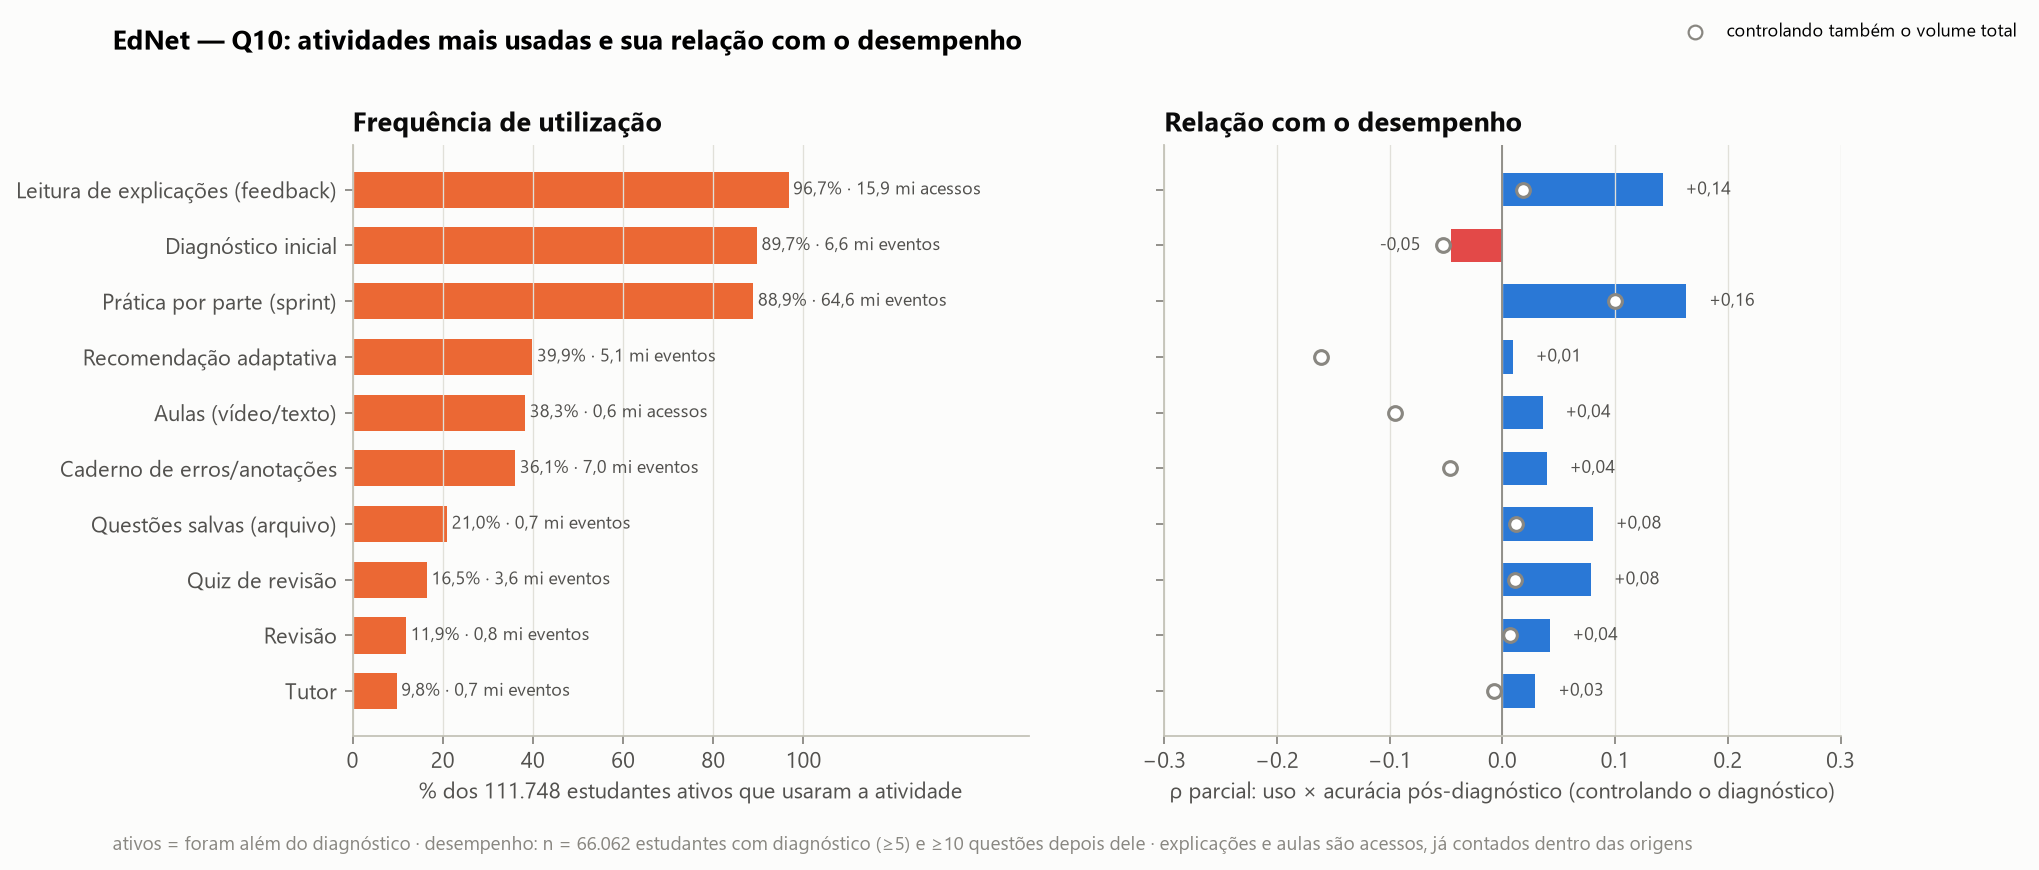

In [8]:
Image(filename=str(C.FIG / "ednet" / "Q10_atividades_desempenho.png"))

## 3. Conclusão da Q10

| | ARES | EdNet |
|---|---|---|
| **Mais usada** | Responder questões/tarefas: 47,8% dos eventos, 100% dos alunos | Prática por parte: 72,4% dos eventos, 88,9% dos ativos |
| **Relação com o desempenho (observado)** | Vocabulário +0,17, tutorial −0,23; o resto ~0 | Prática +0,16 (+0,10 com volume); explicações +0,14 (+0,02 com volume) |
| **Significância** | **Nenhuma** após Holm (tutorial no limite: 0,054) | p < 0,001 (efeito do n) |
| **Magnitude** | Fraca e incerta | **Fraca** (prática) / desprezível (o resto, com volume) |
| **Causa?** | Não | Não |

**Resposta:** a atividade mais usada é **responder questões/praticar**, nas duas bases. A relação das atividades com o desempenho é **fraca ou inexistente**. No EdNet, só a prática mantém uma associação fraca além de “usar mais a plataforma”.

In [9]:
R_A = json.loads((C.TAB / "ares_resultados.json").read_text(encoding="utf-8"))
R_E = json.loads((C.TAB / "ednet_resultados.json").read_text(encoding="utf-8"))
oa = {r["atividade"]: r for r in R_A["Q10"]["atividades"]}
oe = {r["atividade"]: r for r in R_E["Q10"]["atividades"]}
linhas = []
for r in t_ares.itertuples():
    linhas += [("ARES", r.atividade, "ρ parcial (pré)", oa[r.atividade]["rho_parcial_nota_pos_ctrl_pre"], r[2]),
               ("ARES", r.atividade, "p Holm", oa[r.atividade]["p_parcial_holm"], r[6])]
for r in t_ed.itertuples():
    linhas += [("EdNet", r.atividade, "ρ parcial (diag + volume)", oe[r.atividade]["rho_parcial_ctrl_diag_e_volume"], r[3])]
for r in uso_e.itertuples():
    linhas += [("EdNet", r.atividade, "% ativos que usam", oe[r.atividade]["pct_estudantes_ativos_que_usam"], r[6])]
conf = pd.DataFrame(linhas, columns=["base", "atividade", "medida", "oficial", "notebook"])
conf["confere"] = np.isclose(conf["oficial"].astype(float), conf["notebook"].astype(float), atol=1e-3)
print(f"{conf['confere'].sum()}/{len(conf)} valores conferem")
assert conf["confere"].all()
print("✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.")

40/40 valores conferem
✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.


**Próximo:** `08_comparacao_e_recomendacoes.ipynb`.